# Validación cruzada dejando un sujeto fuera (LOSO) — CPC–xLSTM a 12 Hz

**Proyecto Integrador — Equipo 1**

En `06_CPC_fs_configurable.ipynb` se eligió la mejor configuración con **dos sujetos de validación** (11 y 12). Ese diseño tiene un límite: el desempeño cambia mucho entre personas (≈ 0.60 de F1 en el sujeto 11 y ≈ 0.48 en el 12), así que con dos sujetos no se puede saber cuánto variaría con otras personas ni si diferencias de 0.02–0.03 entre modelos son reales.

Este notebook **no busca una configuración nueva**: toma la configuración ganadora del notebook 06 a 12 Hz y la evalúa con **validación cruzada dejando un sujeto fuera** (*leave-one-subject-out*, LOSO) sobre los 12 sujetos de entrenamiento y validación.

## Preguntas que responde

1. ¿Cuál es el desempeño esperado en una **persona nueva**, y cuánto varía de una persona a otra?
2. ¿El preentrenamiento CPC mejora el ajuste fino **de forma consistente entre sujetos**, o la ventaja del notebook 06 dependía de los dos sujetos de validación?
3. ¿Cuánto supera el modelo a las características manuales y a la misma red sin entrenar, sujeto por sujeto?
4. ¿Qué sujetos y qué actividades son los más difíciles?

## Diseño

| Elemento | Decisión | Por qué |
|---|---|---|
| Sujetos | 1–12 en la validación cruzada; **13 y 14 no se usan** | Quedan reservados para la prueba final, que sigue cerrada |
| Rondas | 12: en cada una, **un sujeto se evalúa** y no participa en nada más | Mide la generalización a una persona nueva, 12 veces |
| Validación interna | En cada ronda, **otro sujeto** (el siguiente en la lista) sólo decide cuándo parar el entrenamiento | La parada temprana no puede mirar al sujeto evaluado; así el protocolo es el mismo del notebook 06: 10 sujetos entrenan, 1 decide y 1 evalúa |
| Escalador | Se **reajusta en cada ronda** con los 10 sujetos de entrenamiento | El escalador exportado se ajustó con los sujetos 1–10; usarlo filtraría información de los sujetos evaluados |
| Configuración | sLSTM, horizonte de 1 s, negativos del mismo sujeto, representación `c_T`, recortes aleatorios | La mejor del notebook 06 a 12 Hz; queda **congelada**, sin barrido dentro de las rondas |
| Métodos por ronda | Ajuste fino preentrenado, ajuste fino desde cero, CPC congelado con sonda lineal, red sin entrenar con sonda lineal y características manuales con sonda lineal | Comparaciones emparejadas en los mismos sujetos |
| Semillas | `SEEDS = (0, 1)`; primero se completan las 12 rondas de la semilla 0 | Si la ejecución se interrumpe, la semilla 0 completa ya es suficiente para concluir |

## Cómo ejecutarlo

- Requiere la exportación del Avance 2 a 12 Hz (`notebooks/_cache/avance2/fs12/`).
- Tiempo estimado: ≈ 30 min por ronda y semilla en una Mac con Apple Silicon, es decir, ≈ 6 h por semilla y ≈ 12–13 h con dos. La sección 4 mide el tiempo real y estima la hora de término.
- Se recomienda ejecutarlo desde la terminal, sin suspender el equipo:

```bash
cd notebooks
caffeinate -i ../.venv/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 07_LOSO_CPC_fs12.ipynb
```

- Cada ronda se guarda en `checkpoints/cpc07_loso_fs12/` al terminar. Si la ejecución se interrumpe, al volver a ejecutar se saltan las rondas terminadas (`RERUN = False`).
- El avance se puede seguir mientras corre con `tail -f checkpoints/cpc07_loso_fs12/progreso.log`.

## Flujo

1. Configuración
2. Datos
3. Modelo (las mismas clases del notebook 06)
4. Verificaciones y estimación de tiempo
5. Herramientas de entrenamiento y evaluación
6. Ejecución de las rondas
7. Resultados por sujeto
8. Comparaciones emparejadas
9. Desempeño por actividad
10. ¿Qué tan bien predice CPC la señal?
11. Cómo leer los resultados

# 1. Configuración

In [1]:
import copy, json, math, time
from dataclasses import asdict, dataclass
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from scipy.stats import wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Diseño -----------------------------
TARGET_FS = 12
QUICK = False                          # True = corrida de humo (2 rondas, pocas épocas, carpeta aparte)
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
SEEDS = (0, 1)

# ----------------------------- Configuración congelada (mejor del notebook 06 a 12 Hz) -----------------------------
KIND = "sLSTM"
HORIZON_S = 1.0                        # horizonte B
BATCH_MODE = "mismo_sujeto"
REP = "c_T"
MAX_PRED_HEADS = 12

# ----------------------------- Entrenamiento (iguales al notebook 06) -----------------------------
EPOCHS_MAX, EVAL_EVERY, PATIENCE = 20, 2, 3
BATCH_SIZE, LR, GRAD_CLIP = 128, 5e-4, 1.0
PROBE_TRAIN_MAX = 15_000
FINETUNE_EPOCHS, FINETUNE_PATIENCE, FINETUNE_BATCH = 15, 3, 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
SCALER_FIT_POINTS = 250_000
RERUN = False
SEED_DATA = 0
DEVICE_OVERRIDE = None

FOLDS = CV_SUBJECTS
STEPS_CAP = EVAL_CAP = FT_TRAIN_CAP = None
if QUICK:
    FOLDS, SEEDS = (1, 2), (0,)
    EPOCHS_MAX, EVAL_EVERY, PATIENCE = 2, 1, 1
    PROBE_TRAIN_MAX, STEPS_CAP, EVAL_CAP, FT_TRAIN_CAP, FINETUNE_EPOCHS = 2_000, 4, 1_500, 2_000, 1
# ---------------------------------------------------------------------------

if DEVICE_OVERRIDE:
    DEVICE = torch.device(DEVICE_OVERRIDE)
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EXPORT_DIR = REPO_DIR / "notebooks" / "_cache" / "avance2" / f"fs{TARGET_FS}"
TAG = f"fs{TARGET_FS}" + ("_quick" if QUICK else "")
RUN_DIR = REPO_DIR / "checkpoints" / f"cpc07_loso_{TAG}"
SUMMARY_CSV = REPO_DIR / "notebooks" / "_cache" / f"cpc07_loso_{TAG}_resultados.csv"
LOG_FILE = RUN_DIR / "progreso.log"
RUN_DIR.mkdir(parents=True, exist_ok=True)
assert (EXPORT_DIR / "metadata.json").exists(), f"Falta la exportación {EXPORT_DIR.relative_to(REPO_DIR)}"
assert not set(CV_SUBJECTS) & set(TEST_SUBJECTS)

def horizons_for(seconds, fs=TARGET_FS, max_heads=MAX_PRED_HEADS):
    n = max(1, int(round(seconds * fs)))
    if n <= max_heads:
        return tuple(range(1, n + 1))
    return tuple(int(k) for k in np.unique(np.round(np.linspace(n / max_heads, n, max_heads)).astype(int)))

HORIZONS = horizons_for(HORIZON_S)
METHODS = ["ajuste fino preentrenado", "ajuste fino desde cero", "CPC congelado (sonda)",
           "red sin entrenar (sonda)", "características manuales (sonda)"]

def inner_validation_subject(held_out):
    """El siguiente sujeto de la lista (circular) decide la parada temprana."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]

print("PyTorch:", torch.__version__, "| dispositivo:", DEVICE, "| QUICK:", QUICK)
print("Corridas:", RUN_DIR.relative_to(REPO_DIR))
print(f"Configuración: {KIND} · horizontes {HORIZONS} ({1000 * HORIZONS[-1] / TARGET_FS:.0f} ms) · {BATCH_MODE} · {REP}")
display(pd.DataFrame([{"ronda (sujeto evaluado)": s, "validación interna": inner_validation_subject(s),
                       "entrenamiento": ", ".join(map(str, sorted(set(CV_SUBJECTS) - {s, inner_validation_subject(s)})))}
                      for s in FOLDS]).set_index("ronda (sujeto evaluado)"))

PyTorch: 2.11.0 | dispositivo: mps | QUICK: False
Corridas: checkpoints/cpc07_loso_fs12
Configuración: sLSTM · horizontes (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12) (1000 ms) · mismo_sujeto · c_T


,validación interna,entrenamiento
ronda (sujeto evaluado),,
1,2,"3, 4, 5, 6, 7, 8, 9, 10, 11, 12"
2,3,"1, 4, 5, 6, 7, 8, 9, 10, 11, 12"
3,4,"1, 2, 5, 6, 7, 8, 9, 10, 11, 12"
4,5,"1, 2, 3, 6, 7, 8, 9, 10, 11, 12"
5,6,"1, 2, 3, 4, 7, 8, 9, 10, 11, 12"
6,7,"1, 2, 3, 4, 5, 8, 9, 10, 11, 12"
7,8,"1, 2, 3, 4, 5, 6, 9, 10, 11, 12"
8,9,"1, 2, 3, 4, 5, 6, 7, 10, 11, 12"
9,10,"1, 2, 3, 4, 5, 6, 7, 8, 11, 12"


# 2. Datos

Se lee la serie **sin escalar** de la exportación del Avance 2, porque el escalador se reajusta en cada ronda. Sólo se usan los sujetos 1–12; las ventanas de los sujetos 13 y 14 se descartan desde aquí.

El escalador es el mismo procedimiento del Avance 2 (`clip` en los cuantiles 0.1 % y 99.9 %, `log1p` y centrado con mediana e IQR, por canal), ajustado con una muestra de 250 000 instantes de los 10 sujetos de entrenamiento de cada ronda. La celda compara el escalador ajustado con los sujetos 1–10 contra el exportado, que se ajustó con esos mismos sujetos: deben coincidir casi exactamente.

In [2]:
meta = json.loads((EXPORT_DIR / "metadata.json").read_text())
assert meta["target_fs"] == TARGET_FS and meta["label_rule"] == "final_instant"
with np.load(EXPORT_DIR / "series.npz", allow_pickle=False) as stored:
    signals_raw, labels_series, offsets = stored["signals"], stored["labels"], stored["offsets"]
N_CH, WIN, TAIL, LABELS = signals_raw.shape[1], meta["window_len"], meta["tail_steps"], meta["label_order"]

trials = pd.read_csv(EXPORT_DIR / "trials.csv")
cpc_index = pd.read_csv(EXPORT_DIR / "cpc_index.csv.gz")
sup_index = pd.read_csv(EXPORT_DIR / "supervised_index.csv.gz")
features = pd.read_csv(EXPORT_DIR / "features.csv.gz")
FEATURE_COLUMNS = meta["feature_columns"]
assert (features[["trial_idx", "end_step"]].to_numpy() == sup_index[["trial_idx", "end_step"]].to_numpy()).all()

sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and not cpc_cv["subject"].isin(TEST_SUBJECTS).any()


def fit_scaler(train_subjects, seed=SEED_DATA):
    """clip (q0.1 %, q99.9 %) + log1p + (x − mediana) / IQR, por canal, con instantes de los sujetos dados."""
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)]
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    logged = np.log1p(np.clip(sample, lower, upper))
    q25, center, q75 = np.percentile(logged, [25, 50, 75], axis=0)
    scale = np.where(q75 - q25 > 0, q75 - q25, 1.0)
    return {k: v.astype(np.float32).tolist() for k, v in
            {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params):
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.log1p(np.clip(signals_raw, lower, upper)) - center) / scale).astype(np.float32)


S_T = None
WIN_RANGE = torch.arange(WIN, device=DEVICE)

def set_series(scaled):
    """Sube al dispositivo la serie escalada de la ronda actual."""
    global S_T
    S_T = torch.from_numpy(np.ascontiguousarray(scaled.T)).to(DEVICE)

def starts_of(frame):
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()

def get_windows(starts):
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


# Control: con los sujetos 1–10, el escalador debe reproducir el exportado.
check = fit_scaler(tuple(range(1, 11)))
exported = meta["preprocessing"]
gaps = {k: float(np.max(np.abs(np.asarray(check[k]) - np.asarray(exported[k])) / np.maximum(np.abs(exported[k]), 1e-6)))
        for k in ("lower", "upper", "center", "scale")}
print("Diferencia relativa máxima con el escalador exportado:", {k: f"{v:.1%}" for k, v in gaps.items()})
assert gaps["center"] < 0.02 and gaps["scale"] < 0.03

counts = pd.crosstab(sup_cv["subject"], sup_cv["target"]).rename(columns=dict(enumerate(LABELS)))
counts["total"] = counts.sum(axis=1)
print("Ventanas supervisadas por sujeto (las que se evalúan cuando ese sujeto queda fuera):")
display(counts.T)

Diferencia relativa máxima con el escalador exportado: {'lower': '0.7%', 'upper': '3.2%', 'center': '1.8%', 'scale': '1.3%'}
Ventanas supervisadas por sujeto (las que se evalúan cuando ese sujeto queda fuera):


subject,1,2,3,4,5,6,7,8,9,10,11,12
target,,,,,,,,,,,,
N,2359,1547,1839,1705,1615,1683,2058,1857,2230,1653,2623,1660
LF,419,338,395,441,539,371,450,513,394,365,562,358
K,694,213,347,270,327,302,324,321,266,271,984,326
PT,654,504,612,618,679,579,668,774,608,724,744,620
LT,412,432,413,391,451,361,441,423,381,325,399,356
W,195,359,370,340,435,397,315,441,318,353,258,451
PF,343,240,318,258,356,266,346,390,311,326,384,265
total,5076,3633,4294,4023,4402,3959,4602,4719,4508,4017,5954,4036


# 3. Modelo

Las clases son **exactamente** las del notebook 06 (sección 3), donde se explican: encoder causal, `g_ar` (GRU, sLSTM o mLSTM), predictor de horizontes, InfoNCE y `CPCModel`. Aquí sólo se usa la sLSTM.

In [3]:
@dataclass
class CPCConfig:
    """
    Hiperparámetros de CPC (los mismos del notebook 01), más `pred_horizons`:
    la lista de horizontes k que se predicen. Vacía = k = 1..n_pred_steps, el comportamiento original.
    """
    # --- entrada ---
    n_channels: int = 6

    # --- g_enc: encoder convolucional ---
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2

    # --- g_ar: modelo autorregresivo ---
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2

    # --- predicción / pérdida contrastiva ---
    n_pred_steps: int = 12                  # K: número de horizontes
    n_anchors: int = 4                      # nº de instantes de anclaje por batch de entrenamiento
    pred_horizons: tuple = ()               # NUEVO: horizontes k (en pasos); vacío = 1..n_pred_steps

    @property
    def horizons(self) -> tuple:
        return tuple(self.pred_horizons) or tuple(range(1, self.n_pred_steps + 1))

    @property
    def z_dim(self) -> int:
        return self.enc_channels[-1]

    @property
    def c_dim(self) -> int:
        return self.ar_hidden_size

In [4]:
class CausalEncoder(nn.Module):
    """g_enc causal: bloques Conv1d -> ReLU -> Dropout sin stride (Haresamudram et al., 2020),
    con relleno sólo a la izquierda: z_t depende de x_{t-3..t}, nunca del futuro.

        x: (B, n_channels, T)  -->  z: (B, z_dim, T)
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z

In [5]:
class AutoRegressive(nn.Module):
    """
    g_ar: modelo autorregresivo genérico (GRU multicapa).

        z: (B, L, z_dim)  -->  c: (B, L, c_dim)

    Los parámetros de GRU se especifican en la clase cfg. De acuerdo al paper: 
    - input_size: 128
    - hidden_Size: 256
    - num_layer: 2

    c[:, t] resume z[:, :t+1] de forma causal (una GRU nunca mira el futuro),
    que es la propiedad necesaria para usar c_t como predictor de z_{t+k}.

    Arquitectura (Haresamudram, Essa & Plötz, 2020): GRU de 2 capas con 256
    unidades ocultas y dropout entre capas.
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.gru = nn.GRU(
            input_size=cfg.z_dim,
            hidden_size=cfg.ar_hidden_size,
            num_layers=cfg.ar_num_layers,
            dropout=cfg.ar_dropout if cfg.ar_num_layers > 1 else 0.0,  # PyTorch exige 0 si num_layers==1
            batch_first=True,
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        c, _ = self.gru(z)        # c: (B, L, c_dim) - Hace un loop sobre todo el eje temporal toma el c_{t-1} e incorpora el nuevo paso z_t
        return c

In [6]:
class Predictor(nn.Module):
    """
    Cabezas de predicción log-bilineal: una W_k (sin sesgo) por cada horizonte de cfg.horizons.

        c_t: (B, c_dim) -> (n_horizontes, B, z_dim),  con pred_k = W_k c_t ≈ z_{t+k}
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.horizons = cfg.horizons
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in self.horizons])

    def forward(self, c_t: torch.Tensor) -> torch.Tensor:
        return torch.stack([head(c_t) for head in self.heads], dim=0)


class InfoNCE(nn.Module):
    """
    Pérdida contrastiva de CPC (Ec. 4) con negativos de minibatch, para cada horizonte de la lista.
    Para el horizonte k, el positivo de la secuencia i es z_{t+k}^(i) y los negativos son los
    z_{t+k}^(j) (j != i) de las otras secuencias del batch.
    """

    def __init__(self, horizons: tuple):
        super().__init__()
        self.horizons = tuple(horizons)

    def forward(self, preds: torch.Tensor, z: torch.Tensor, t: int):
        """
        preds: (n_horizontes, B, z_dim) · z: (B, L, z_dim) · t: instante de anclaje
        Devuelve (loss_mean, loss_per_k, acc_per_k), los dos últimos de forma (n_horizontes,).
        """
        H, B, _ = preds.shape
        target = torch.arange(B, device=preds.device)
        loss_per_k = torch.zeros(H, device=preds.device)
        acc_per_k = torch.zeros(H, device=preds.device)
        for j, k in enumerate(self.horizons):
            logits = preds[j] @ z[:, t + k, :].t()          # (B, B): S_ij = pred_i · z_{t+k}^(j)
            loss_per_k[j] = F.cross_entropy(logits, target)
            acc_per_k[j] = (logits.argmax(dim=1) == target).float().mean()
        return loss_per_k.mean(), loss_per_k, acc_per_k.detach()


class CPCModel(nn.Module):
    """Modelo CPC completo (Encoder + g_ar + Predictor + InfoNCE), con horizontes de cfg.horizons."""

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)          # encoder causal (sección 3.1)
        self.ar = AutoRegressive(cfg)
        self.predictor = Predictor(cfg)
        self.info_nce_loss = InfoNCE(cfg.horizons)

    def encode(self, x: torch.Tensor):
        """x: (B, n_channels, T) -> z: (B, T, z_dim), c: (B, T, c_dim)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)

    def anchor_range(self, L: int):
        lo, hi = max(1, L // 8), L - max(self.cfg.horizons)   # deja sitio para leer z_{t+k_máx}
        if hi <= lo:
            raise ValueError(f"Ventana T={L} demasiado corta para el horizonte {max(self.cfg.horizons)}")
        return lo, hi

    def info_nce(self, x: torch.Tensor, anchors=None):
        z, c = self.encode(x)
        if anchors is None:
            anchors = torch.randint(*self.anchor_range(z.shape[1]), size=(self.cfg.n_anchors,)).tolist()
        losses, accs = [], []
        for t in anchors:
            _, loss_per_k, acc_per_k = self.info_nce_loss(self.predictor(c[:, t, :]), z, t)
            losses.append(loss_per_k)
            accs.append(acc_per_k)
        loss_per_k = torch.stack(losses).mean(dim=0)
        acc_per_k = torch.stack(accs).mean(dim=0)
        return loss_per_k.mean(), loss_per_k, acc_per_k

In [7]:
class BlockDiagonalLinear(nn.Module):
    """
    Capa lineal con matriz de pesos block-diagonal: cada "head" (bloque) solo mezcla sus propias
    dimensiones. Es la forma en que xLSTM limita la mezcla entre celdas (sLSTM) o abarata las
    proyecciones q, k, v (mLSTM).

        x: (..., dim) -> (..., dim)     con n_blocks bloques de tamaño dim // n_blocks
    """

    def __init__(self, dim: int, n_blocks: int, bias: bool = True):
        super().__init__()
        assert dim % n_blocks == 0, "dim debe ser múltiplo de n_blocks"
        self.n_blocks, self.block = n_blocks, dim // n_blocks
        self.weight = nn.Parameter(torch.randn(n_blocks, self.block, self.block) / math.sqrt(self.block))
        self.bias = nn.Parameter(torch.zeros(dim)) if bias else None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        shape = x.shape
        x = x.reshape(*shape[:-1], self.n_blocks, self.block)
        y = torch.einsum("...nd,ned->...ne", x, self.weight).reshape(shape)
        return y if self.bias is None else y + self.bias

In [8]:
class sLSTMCell(nn.Module):
    """
    Celda sLSTM (Beck et al. 2024, Ec. 34-40, con estabilización Ec. 15-17).

        x: (B, T, dim) -> h: (B, T, dim)

    Diferencias con la LSTM clásica:
      - compuerta de entrada EXPONENCIAL  i_t = exp(ĩ_t)  (permite "revisar" decisiones de memoria)
      - estado normalizador  n_t = f_t n_{t-1} + i_t,  y  h_t = o_t * c_t / n_t
      - estado estabilizador m_t para que exp() no desborde (no cambia el resultado)
      - memory mixing por heads: la recurrencia R h_{t-1} es block-diagonal (n_heads bloques)

    Es recurrente (no paralelizable): recorre el tiempo paso a paso, igual que la GRU.
    """

    def __init__(self, dim: int, n_heads: int):
        super().__init__()
        self.dim = dim
        self.W = nn.Linear(dim, 4 * dim)                                     # entrada -> z, i, f, o
        self.R = nn.ModuleList([BlockDiagonalLinear(dim, n_heads, bias=False) for _ in range(4)])
        with torch.no_grad():                                                # sesgo de la forget gate en [3, 6]
            self.W.bias[2 * dim:3 * dim] = torch.linspace(3.0, 6.0, dim)    # (Tabla 2 del paper): al inicio "recuerda"

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, D = x.shape
        Wx = self.W(x)                                                       # parte de la entrada, para todo t a la vez
        h = c = n = m = x.new_zeros(B, D)
        outputs = []
        for t in range(T):
            Rh = torch.cat([r(h) for r in self.R], dim=-1)                   # parte recurrente (memory mixing)
            z_pre, i_pre, f_pre, o_pre = (Wx[:, t] + Rh).chunk(4, dim=-1)
            log_f = F.logsigmoid(f_pre)                                      # forget gate sigmoide, en log
            m_new = torch.maximum(log_f + m, i_pre)                          # Ec. 15: estabilizador
            i_gate = torch.exp(i_pre - m_new)                                # Ec. 16: i' (exponencial estabilizada)
            f_gate = torch.exp(log_f + m - m_new)                            # Ec. 17: f'
            c = f_gate * c + i_gate * torch.tanh(z_pre)                      # Ec. 34: estado de celda
            n = f_gate * n + i_gate                                          # Ec. 35: normalizador
            h = torch.sigmoid(o_pre) * c / n                                 # Ec. 36: estado oculto
            m = m_new
            outputs.append(h)
        return torch.stack(outputs, dim=1)

In [9]:
class sLSTMBlock(nn.Module):
    """
    Bloque residual sLSTM con "post up-projection" (Fig. 10 del paper, sin la convolución opcional):

        x -> LayerNorm -> sLSTM (n_heads) -> GroupNorm -> (+x)
          -> LayerNorm -> MLP con compuerta (factor 4/3, GeLU) -> (+x)
    """

    def __init__(self, dim: int, n_heads: int, dropout: float, proj_factor: float = 4 / 3):
        super().__init__()
        inner = int(round(proj_factor * dim))
        self.ln1, self.ln2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.cell = sLSTMCell(dim, n_heads)
        self.gn = nn.GroupNorm(n_heads, dim)                                 # LayerNorm por head
        self.up_a, self.up_b = nn.Linear(dim, inner), nn.Linear(dim, inner)
        self.down = nn.Linear(inner, dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.cell(self.ln1(x))
        h = self.gn(h.reshape(-1, h.shape[-1])).reshape(h.shape)
        x = x + self.drop(h)
        y = self.ln2(x)
        return x + self.drop(self.down(self.up_a(y) * F.gelu(self.up_b(y))))

In [10]:
def mlstm_parallel(q, k, v, i_pre, f_pre, n_heads):
    """
    mLSTM en su forma PARALELA estabilizada (Apéndice A.3, Ec. 79-86): procesa todos los
    instantes a la vez con una matriz T x T, como la atención, pero con compuertas.

        q, k, v      : (B, T, D)        D = n_heads * dh
        i_pre, f_pre : (B, T, n_heads)  pre-activaciones de las compuertas de entrada y olvido
        -> h̃         : (B, T, D)

    Es equivalente a la recurrencia  C_t = f_t C_{t-1} + i_t v_t k_tᵀ,  n_t = f_t n_{t-1} + i_t k_t,
    h̃_t = C_t q_t / max(|n_tᵀ q_t|, 1)  (Ec. 19-21), y causal: el instante i solo usa j <= i.
    """
    B, T, D = q.shape
    dh = D // n_heads
    q, k, v = [x.view(B, T, n_heads, dh).transpose(1, 2) for x in (q, k, v)]   # (B, H, T, dh)
    i_pre, f_pre = i_pre.transpose(1, 2), f_pre.transpose(1, 2)                # (B, H, T)

    log_f = F.logsigmoid(f_pre)
    cum = torch.cumsum(log_f, dim=-1)
    log_F = cum.unsqueeze(-1) - cum.unsqueeze(-2)              # [i, j] = sum_{k=j+1..i} log f_k   (Ec. 101)
    causal = torch.ones(T, T, dtype=torch.bool, device=q.device).tril()
    log_D = (log_F + i_pre.unsqueeze(-2)).masked_fill(~causal, float("-inf"))  # Ec. 79: log F + Ĩ
    m = log_D.amax(dim=-1, keepdim=True)                       # Ec. 80: estabilizador por fila
    D_mat = torch.exp(log_D - m)                               # Ec. 81
    C = (q @ k.transpose(-2, -1)) / math.sqrt(dh) * D_mat      # Ec. 82: scores qkᵀ/√d con compuertas
    n = torch.maximum(C.sum(dim=-1, keepdim=True).abs(), torch.exp(-m))   # Ec. 83-84: normalizador
    h = (C / n) @ v                                            # Ec. 85-86
    return h.transpose(1, 2).reshape(B, T, D)


def mlstm_recurrent(q, k, v, i_pre, f_pre, n_heads):
    """La misma mLSTM en forma RECURRENTE (Ec. 19-21, estabilizada). Solo se usa para verificar."""
    B, T, D = q.shape
    dh = D // n_heads
    q, k, v = [x.view(B, T, n_heads, dh) for x in (q, k, v)]
    k = k / math.sqrt(dh)                                      # Ec. 23: k escalado por 1/√d
    C = q.new_zeros(B, n_heads, dh, dh)
    n = q.new_zeros(B, n_heads, dh)
    m = q.new_full((B, n_heads), float("-inf"))
    out = []
    for t in range(T):
        log_f = F.logsigmoid(f_pre[:, t])
        m_new = torch.maximum(log_f + m, i_pre[:, t])
        i_g = torch.exp(i_pre[:, t] - m_new)[..., None]
        f_g = torch.exp(log_f + m - m_new)[..., None]
        C = f_g[..., None] * C + i_g[..., None] * (v[:, t, :, :, None] @ k[:, t, :, None, :])  # C += i v kᵀ
        n = f_g * n + i_g * k[:, t]
        num = (C @ q[:, t, :, :, None]).squeeze(-1)
        den = torch.maximum((n * q[:, t]).sum(-1, keepdim=True).abs(), torch.exp(-m_new)[..., None])
        out.append(num / den)
        m = m_new
    return torch.stack(out, dim=1).reshape(B, T, D)

In [11]:
class mLSTMBlock(nn.Module):
    """
    Bloque residual mLSTM con "pre up-projection" (Fig. 11 del paper):

        x -> LayerNorm -> proyección x2 en dos ramas:
             rama celda : conv causal (k=4) + Swish -> q, k ; (sin conv) -> v ; compuertas i, f
                          -> mLSTM -> GroupNorm -> + skip aprendible
             rama salida: Swish  (compuerta de salida externa, por componente)
          -> producto de ambas ramas -> proyección de vuelta a dim -> (+x)
    """

    def __init__(self, dim: int, n_heads: int, dropout: float, proj_factor: int = 2,
                 conv_kernel: int = 4, qkv_block: int = 4):
        super().__init__()
        inner = proj_factor * dim
        self.n_heads, self.conv_kernel = n_heads, conv_kernel
        self.ln = nn.LayerNorm(dim)
        self.up_cell, self.up_gate = nn.Linear(dim, inner), nn.Linear(dim, inner)
        self.conv = nn.Conv1d(inner, inner, conv_kernel, groups=inner)       # por dimensión (depthwise)
        self.q = BlockDiagonalLinear(inner, inner // qkv_block)
        self.k = BlockDiagonalLinear(inner, inner // qkv_block)
        self.v = BlockDiagonalLinear(inner, inner // qkv_block)
        self.igate, self.fgate = nn.Linear(3 * inner, n_heads), nn.Linear(3 * inner, n_heads)
        with torch.no_grad():
            self.fgate.bias.copy_(torch.linspace(3.0, 6.0, n_heads))         # forget gate: al inicio recuerda
            nn.init.normal_(self.igate.bias, 0.0, 0.1)                       # input gate: N(0, 0.1) (Tabla 2)
        self.gn = nn.GroupNorm(n_heads, inner)
        self.skip = nn.Parameter(torch.ones(inner))                          # "learnable skip" de la Fig. 11
        self.down = nn.Linear(inner, dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        y = self.ln(x)
        x_cell, x_gate = self.up_cell(y), self.up_gate(y)
        # Convolución CAUSAL: se rellena solo a la izquierda, así el instante t no ve t+1, t+2, ...
        x_conv = F.silu(self.conv(F.pad(x_cell.transpose(1, 2), (self.conv_kernel - 1, 0))).transpose(1, 2))
        q, k, v = self.q(x_conv), self.k(x_conv), self.v(x_cell)
        qkv = torch.cat([q, k, v], dim=-1)
        h = mlstm_parallel(q, k, v, self.igate(qkv), self.fgate(qkv), self.n_heads)
        h = self.gn(h.reshape(-1, h.shape[-1])).reshape(h.shape) + self.skip * x_conv
        return x + self.drop(self.down(h * F.silu(x_gate)))

In [12]:
class xLSTMAutoRegressive(nn.Module):
    """
    g_ar alternativo a la GRU, con la MISMA interfaz que AutoRegressive del notebook 01:

        z: (B, T, z_dim) -> c: (B, T, c_dim)

    Proyecta z_t a c_dim y apila `n_blocks` bloques xLSTM residuales (todos sLSTM o todos mLSTM),
    como la GRU apila 2 capas. Todo es causal: c_t solo depende de z_1..z_t.
    """

    def __init__(self, cfg: CPCConfig, kind: str, n_blocks: int = 2, n_heads: int = 4):
        super().__init__()
        assert kind in ("sLSTM", "mLSTM")
        Block = sLSTMBlock if kind == "sLSTM" else mLSTMBlock
        self.proj = nn.Linear(cfg.z_dim, cfg.c_dim)
        self.blocks = nn.ModuleList([Block(cfg.c_dim, n_heads, cfg.ar_dropout) for _ in range(n_blocks)])
        self.ln_out = nn.LayerNorm(cfg.c_dim)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        x = self.proj(z)
        for block in self.blocks:
            x = block(x)
        return self.ln_out(x)

In [13]:
def build_model(kind: str, horizons: tuple, seed: int, device=None) -> CPCModel:
    """CPC completo con el g_ar elegido. La semilla fija los pesos iniciales (misma semilla = misma red)."""
    cfg = CPCConfig(n_channels=N_CH, n_pred_steps=len(horizons), n_anchors=4, pred_horizons=tuple(horizons))
    torch.manual_seed(seed)
    model = CPCModel(cfg)
    if kind != "GRU":
        model.ar = xLSTMAutoRegressive(cfg, kind)
    return model.to(device or DEVICE)


def summarize(c: torch.Tensor, representation: str) -> torch.Tensor:
    """c: (B, T, c_dim) -> vector por ventana."""
    if representation == "c_T":
        return c[:, -1]
    if representation == "cola":
        return c[:, -TAIL:].mean(dim=1)
    if representation == "media":
        return c.mean(dim=1)
    if representation == "c_T+media":
        return torch.cat([c[:, -1], c.mean(dim=1)], dim=1)
    raise ValueError(representation)

# 4. Verificaciones y estimación de tiempo

1. **Causalidad** del modelo completo desde la entrada: perturbar la señal a partir de `T/2` no debe cambiar nada antes de `T/2`.
2. **Tiempo:** se miden pasos de preentrenamiento y de ajuste fino, y se estima la duración de cada ronda y la hora aproximada de término.

In [14]:
def sync():
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()

set_series(apply_scaler(check))
model = build_model(KIND, HORIZONS, seed=0).eval()
x = torch.randn(4, N_CH, WIN, device=DEVICE)
x_mod = x.clone()
x_mod[:, :, WIN // 2:] += torch.randn_like(x_mod[:, :, WIN // 2:])
with torch.no_grad():
    past = (model.encode(x)[1][:, :WIN // 2] - model.encode(x_mod)[1][:, :WIN // 2]).abs().max().item()
assert past == 0.0, f"Fuga temporal: {past:.2e}"
print("Causalidad desde la entrada: OK")

starts_pool = starts_of(cpc_cv)
model.train()
opt = torch.optim.Adam(model.parameters(), lr=LR)
for it in range(5):
    if it == 2:
        sync(); t0 = time.time()
    loss, _, _ = model.info_nce(get_windows(np.random.default_rng(it).choice(starts_pool, BATCH_SIZE)))
    opt.zero_grad(); loss.backward(); opt.step()
sync()
cpc_step = (time.time() - t0) / 3

head = nn.Linear(model.cfg.c_dim, len(LABELS)).to(DEVICE)
sup_pool = starts_of(sup_cv)
for it in range(5):
    if it == 2:
        sync(); t0 = time.time()
    xb = get_windows(np.random.default_rng(it).choice(sup_pool, FINETUNE_BATCH))
    loss = F.cross_entropy(head(model.encode(xb)[1][:, -1]), torch.zeros(FINETUNE_BATCH, dtype=torch.long, device=DEVICE))
    opt.zero_grad(); loss.backward(); opt.step()
sync()
ft_step = (time.time() - t0) / 3
del model, head, opt

n_steps_cpc = len(cpc_cv) * 10 // 12 // BATCH_SIZE
n_steps_ft = len(sup_cv) * 10 // 12 // FINETUNE_BATCH
# Épocas típicas en el notebook 06: ~12 de CPC y ~9 por cada ajuste fino; + evaluaciones (~4 min).
fold_min = (cpc_step * n_steps_cpc * 12 + ft_step * n_steps_ft * 9 * 2) / 60 + 4
total_h = fold_min * len(FOLDS) * len(SEEDS) / 60
print(f"Paso CPC: {cpc_step:.2f} s · paso de ajuste fino: {ft_step:.2f} s")
print(f"Estimación: ≈ {fold_min:.0f} min por ronda · {len(FOLDS)} rondas × {len(SEEDS)} semillas ≈ {total_h:.1f} h")
print(f"Término aproximado si se ejecuta ahora: {(datetime.now() + timedelta(hours=total_h)):%d/%m %H:%M}")

Causalidad desde la entrada: OK


Paso CPC: 0.21 s · paso de ajuste fino: 0.34 s
Estimación: ≈ 27 min por ronda · 12 rondas × 2 semillas ≈ 10.7 h
Término aproximado si se ejecuta ahora: 15/10 04:05


# 5. Herramientas de entrenamiento y evaluación

Mismas funciones que el notebook 06, pero recibiendo los conjuntos de cada ronda:

- **`make_sets`:** ventanas de entrenamiento (sonda lineal y ajuste fino), del sujeto de validación interna y del sujeto evaluado.
- **`train_cpc`:** preentrenamiento con negativos del mismo sujeto y recortes aleatorios; cada `EVAL_EVERY` épocas mide el F1 de la sonda lineal en el sujeto de **validación interna** y conserva la mejor época.
- **`finetune`:** ajusta el modelo completo con entropía cruzada ponderada por clase y parada temprana con el sujeto de validación interna.
- **`run_fold`:** ejecuta una ronda completa, evalúa los cinco métodos en el sujeto que quedó fuera, guarda las predicciones de cada ventana (`.json`) y los pesos (`.pt`), y escribe una línea en `progreso.log`.

In [15]:
def eval_set(frame, cap=None):
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED_DATA)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def make_sets(train_subjects, inner_val, held_out):
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    return {
        "probe_train": eval_set(train, PROBE_TRAIN_MAX),
        "ft_train": eval_set(train, FT_TRAIN_CAP),
        "val": eval_set(sup_cv[sup_cv["subject"] == inner_val], EVAL_CAP),
        "held": eval_set(sup_cv[sup_cv["subject"] == held_out], EVAL_CAP),
        "val_cpc_starts": starts_of(cpc_cv[cpc_cv["subject"] == inner_val]),
        "n_steps": max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // BATCH_SIZE),
    }


class CPCBatchSampler:
    """Inicios de ventana al azar en los ensayos de los sujetos dados; con `mismo_sujeto`, un sujeto por batch."""

    def __init__(self, subjects, batch_mode, seed):
        self.rng, self.batch_mode = np.random.default_rng(seed), batch_mode
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        self.starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: self.starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()

    def batch(self):
        if self.batch_mode == "mezclado":
            return self.rng.choice(self.starts, BATCH_SIZE, replace=False)
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, BATCH_SIZE, replace=len(pool) < BATCH_SIZE)


def metrics(y_true, y_pred):
    ids = list(range(len(LABELS)))
    return {"f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "f1_per_class": f1_score(y_true, y_pred, labels=ids, average=None, zero_division=0).tolist()}


def summarize(c, representation=REP):
    if representation == "c_T":
        return c[:, -1]
    if representation == "cola":
        return c[:, -TAIL:].mean(dim=1)
    if representation == "media":
        return c.mean(dim=1)
    return torch.cat([c[:, -1], c.mean(dim=1)], dim=1)


@torch.no_grad()
def extract(model, starts, batch=512):
    model.eval()
    return np.concatenate([summarize(model.encode(get_windows(starts[s:s + batch]))[1]).float().cpu().numpy()
                           for s in range(0, len(starts), batch)])


def fit_probe(X, y):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X, y)


def probe_predictions(model, sets, targets=("held",)):
    clf = fit_probe(extract(model, sets["probe_train"]["starts"]), sets["probe_train"]["y"])
    return {k: clf.predict(extract(model, sets[k]["starts"])) for k in targets}


@torch.no_grad()
def contrastive_eval(model, starts_pool, n_batches=20):
    model.eval()
    g = np.random.default_rng(SEED_DATA)
    lo, hi = model.anchor_range(WIN)
    losses = []
    for _ in range(min(n_batches, len(starts_pool) // BATCH_SIZE)):
        anchors = g.integers(lo, hi, size=model.cfg.n_anchors).tolist()
        losses.append(model.info_nce(get_windows(g.choice(starts_pool, BATCH_SIZE, replace=False)), anchors=anchors)[0].item())
    return float(np.mean(losses)) if losses else float("nan")


def train_cpc(train_subjects, sets, seed):
    model = build_model(KIND, HORIZONS, seed)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sampler = CPCBatchSampler(train_subjects, BATCH_MODE, seed)
    n_steps = min(sets["n_steps"], STEPS_CAP) if STEPS_CAP else sets["n_steps"]
    torch.manual_seed(seed)
    best, bad, history, t0 = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0, [], time.time()
    for epoch in range(1, EPOCHS_MAX + 1):
        model.train()
        run_loss = 0.0
        for _ in range(n_steps):
            loss, _, _ = model.info_nce(get_windows(sampler.batch()))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            run_loss += loss.item()
        row = {"epoch": epoch, "train_loss": run_loss / n_steps, "val_loss": contrastive_eval(model, sets["val_cpc_starts"])}
        if epoch % EVAL_EVERY == 0 or epoch == EPOCHS_MAX:
            row["f1_val"] = f1_score(sets["val"]["y"], probe_predictions(model, sets, ("val",))["val"], average="macro")
            if row["f1_val"] > best["f1"] + 1e-4:
                best, bad = {"f1": row["f1_val"], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        history.append(row)
        if bad >= PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "minutes": (time.time() - t0) / 60}


class CPCClassifier(nn.Module):
    def __init__(self, cpc_model, representation=REP, n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar, self.representation = cpc_model.encoder, cpc_model.ar, representation
        dim = cpc_model.cfg.c_dim * (2 if representation == "c_T+media" else 1)
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def forward(self, x):
        return self.head(summarize(self.ar(self.encoder(x).transpose(1, 2)), self.representation))


@torch.no_grad()
def predict(model, starts, batch=512):
    model.eval()
    return np.concatenate([model(get_windows(starts[s:s + batch])).argmax(1).cpu().numpy()
                           for s in range(0, len(starts), batch)])


def finetune(base, sets, seed):
    torch.manual_seed(seed)
    model = CPCClassifier(base).to(DEVICE)
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    counts = np.bincount(train["y"], minlength=len(LABELS))
    weights = torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng = np.random.default_rng(seed)
    best, bad, history, t0 = {"f1": -1.0, "epoch": 0, "state": None}, 0, [], time.time()
    for epoch in range(1, FINETUNE_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1_val = f1_score(sets["val"]["y"], predict(model, sets["val"]["starts"]), average="macro")
        history.append({"epoch": epoch, "f1_val": f1_val})
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
        if bad >= FINETUNE_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "minutes": (time.time() - t0) / 60}


def log(message):
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


def run_fold(held_out, seed):
    path = RUN_DIR / f"ronda_s{held_out:02d}_semilla{seed}.json"
    if path.exists() and not RERUN:
        r = json.loads(path.read_text())
        print(f"Sujeto {held_out:2d}, semilla {seed}: guardada | "
              + " | ".join(f"{m}: {r['metrics'][m]['f1_macro']:.3f}" for m in METHODS[:2]))
        return
    t0 = time.time()
    inner_val = inner_validation_subject(held_out)
    train_subjects = tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))
    scaler = fit_scaler(train_subjects)
    set_series(apply_scaler(scaler))
    sets = make_sets(train_subjects, inner_val, held_out)
    y_held = sets["held"]["y"]
    preds, info = {}, {}

    cpc_model, info["cpc"] = train_cpc(train_subjects, sets, seed)
    preds["CPC congelado (sonda)"] = probe_predictions(cpc_model, sets)["held"]
    preds["red sin entrenar (sonda)"] = probe_predictions(build_model(KIND, HORIZONS, seed), sets)["held"]
    tab = fit_probe(features.loc[sets["probe_train"]["index"], FEATURE_COLUMNS].to_numpy(np.float32), sets["probe_train"]["y"])
    preds["características manuales (sonda)"] = tab.predict(features.loc[sets["held"]["index"], FEATURE_COLUMNS].to_numpy(np.float32))

    cpc_state = copy.deepcopy(cpc_model.state_dict())
    ft_pre, info["ajuste fino preentrenado"] = finetune(cpc_model, sets, seed)
    preds["ajuste fino preentrenado"] = predict(ft_pre, sets["held"]["starts"])
    ft_scratch, info["ajuste fino desde cero"] = finetune(build_model(KIND, HORIZONS, seed), sets, seed)
    preds["ajuste fino desde cero"] = predict(ft_scratch, sets["held"]["starts"])

    result = {"held_out": held_out, "inner_val": inner_val, "train_subjects": list(train_subjects), "seed": seed,
              "config": {"kind": KIND, "horizons": list(HORIZONS), "batch_mode": BATCH_MODE, "rep": REP, "target_fs": TARGET_FS},
              "scaler": scaler, "info": info, "minutes": (time.time() - t0) / 60,
              "metrics": {m: metrics(y_held, preds[m]) for m in METHODS},
              "y": y_held.tolist(), "pred": {m: preds[m].tolist() for m in METHODS}}
    torch.save({"cpc": cpc_state, "ajuste fino preentrenado": ft_pre.state_dict(),
                "ajuste fino desde cero": ft_scratch.state_dict(), "scaler": scaler, "config": result["config"]},
               path.with_suffix(".pt"))
    path.write_text(json.dumps(result))
    log(f"sujeto {held_out:2d} (val. interna {inner_val:2d}), semilla {seed} | {result['minutes']:.0f} min | "
        + " | ".join(f"{m}: {result['metrics'][m]['f1_macro']:.3f}" for m in METHODS))
    del cpc_model, ft_pre, ft_scratch

# 6. Ejecución de las rondas

Primero las 12 rondas con la semilla 0 y después con la semilla 1. Cada ronda se guarda al terminar; si la ejecución se interrumpe, al volver a ejecutar se continúa donde se quedó. Cada línea del registro muestra el F1 macro de los cinco métodos en el sujeto evaluado.

In [16]:
t_start = time.time()
log(f"inicio: {len(FOLDS)} rondas × {len(SEEDS)} semillas")
for seed in SEEDS:
    for held_out in FOLDS:
        run_fold(held_out, seed)
log(f"fin: {(time.time() - t_start) / 3600:.1f} h en esta ejecución")

2026-10-14 17:26 | inicio: 12 rondas × 2 semillas
Sujeto  1, semilla 0: guardada | ajuste fino preentrenado: 0.424 | ajuste fino desde cero: 0.426
Sujeto  2, semilla 0: guardada | ajuste fino preentrenado: 0.337 | ajuste fino desde cero: 0.322
Sujeto  3, semilla 0: guardada | ajuste fino preentrenado: 0.547 | ajuste fino desde cero: 0.496
Sujeto  4, semilla 0: guardada | ajuste fino preentrenado: 0.422 | ajuste fino desde cero: 0.395
Sujeto  5, semilla 0: guardada | ajuste fino preentrenado: 0.429 | ajuste fino desde cero: 0.389
Sujeto  6, semilla 0: guardada | ajuste fino preentrenado: 0.397 | ajuste fino desde cero: 0.413
Sujeto  7, semilla 0: guardada | ajuste fino preentrenado: 0.333 | ajuste fino desde cero: 0.284
Sujeto  8, semilla 0: guardada | ajuste fino preentrenado: 0.473 | ajuste fino desde cero: 0.469
Sujeto  9, semilla 0: guardada | ajuste fino preentrenado: 0.469 | ajuste fino desde cero: 0.456
Sujeto 10, semilla 0: guardada | ajuste fino preentrenado: 0.397 | ajuste fin

**Registro completo del entrenamiento.** Cuando las rondas ya estaban guardadas, la celda anterior sólo muestra su resumen; el registro con la hora, la duración y el F1 de cada ronda, escrito durante el entrenamiento original, está en `progreso.log`:

In [17]:
print(LOG_FILE.read_text())

2026-10-13 23:25 | inicio: 12 rondas × 2 semillas
2026-10-13 23:38 | sujeto  1 (val. interna  2), semilla 0 | 13 min | ajuste fino preentrenado: 0.424 | ajuste fino desde cero: 0.426 | CPC congelado (sonda): 0.427 | red sin entrenar (sonda): 0.395 | características manuales (sonda): 0.391
2026-10-14 00:12 | sujeto  2 (val. interna  3), semilla 0 | 34 min | ajuste fino preentrenado: 0.337 | ajuste fino desde cero: 0.322 | CPC congelado (sonda): 0.319 | red sin entrenar (sonda): 0.321 | características manuales (sonda): 0.363
2026-10-14 00:36 | sujeto  3 (val. interna  4), semilla 0 | 24 min | ajuste fino preentrenado: 0.547 | ajuste fino desde cero: 0.496 | CPC congelado (sonda): 0.452 | red sin entrenar (sonda): 0.449 | características manuales (sonda): 0.456
2026-10-14 01:00 | sujeto  4 (val. interna  5), semilla 0 | 24 min | ajuste fino preentrenado: 0.422 | ajuste fino desde cero: 0.395 | CPC congelado (sonda): 0.364 | red sin entrenar (sonda): 0.369 | características manuales (sond

# 7. Resultados por sujeto

Cada fila es un sujeto evaluado como persona nueva (promedio de las semillas disponibles). La última fila resume a los 12 sujetos: media ± desviación **entre personas**, que es la variación que importa para generalizar.

Rondas terminadas: 24 | semillas: [0, 1] | sujetos: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


método,ajuste fino preentrenado,ajuste fino desde cero,CPC congelado (sonda),red sin entrenar (sonda),características manuales (sonda)
1,0.428,0.423,0.414,0.407,0.391
2,0.365,0.319,0.317,0.322,0.363
3,0.533,0.497,0.467,0.465,0.456
4,0.424,0.393,0.364,0.372,0.379
5,0.424,0.391,0.375,0.372,0.357
6,0.369,0.394,0.326,0.310,0.339
7,0.338,0.288,0.376,0.285,0.317
8,0.473,0.468,0.416,0.434,0.405
9,0.457,0.445,0.411,0.394,0.366
10,0.405,0.434,0.320,0.376,0.346


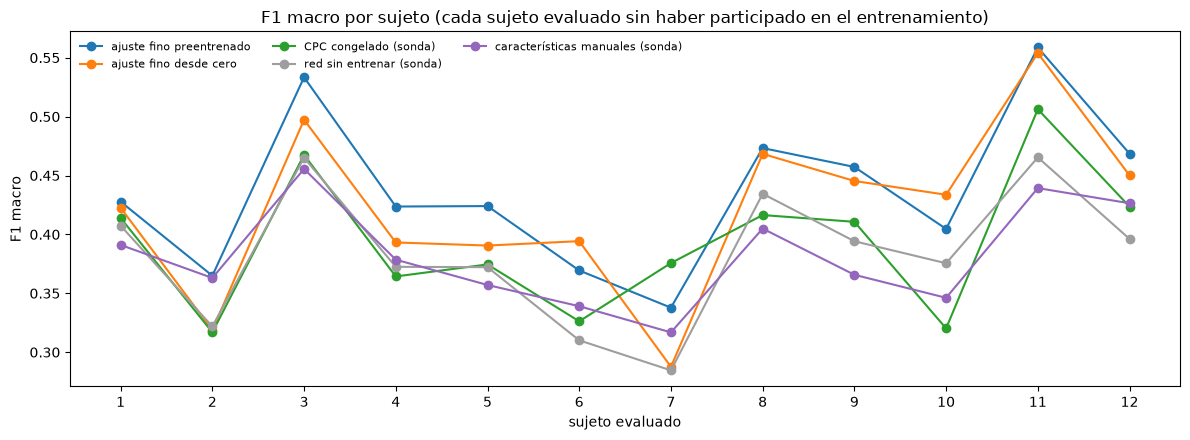

Ajuste fino preentrenado: diferencia media absoluta entre semillas por sujeto = 0.028


In [18]:
runs = [json.loads(p.read_text()) for p in sorted(RUN_DIR.glob("ronda_*.json"))]
assert runs, "Todavía no hay rondas terminadas."
rows = [{"sujeto": r["held_out"], "semilla": r["seed"], "método": m, "F1": r["metrics"][m]["f1_macro"],
         "bal_acc": r["metrics"][m]["balanced_accuracy"], **{f"F1 {l}": f for l, f in zip(LABELS, r["metrics"][m]["f1_per_class"])}}
        for r in runs for m in METHODS]
results = pd.DataFrame(rows)
results.to_csv(SUMMARY_CSV, index=False)
print(f"Rondas terminadas: {len(runs)} | semillas: {sorted(map(int, results['semilla'].unique()))} | "
      f"sujetos: {sorted(map(int, results['sujeto'].unique()))}")

by_subject = results.groupby(["sujeto", "método"])["F1"].mean().unstack()[METHODS]
summary = pd.DataFrame({"media": by_subject.mean(), "desv. entre sujetos": by_subject.std(), "mínimo": by_subject.min(),
                        "máximo": by_subject.max()}).T
display(pd.concat([by_subject, summary]).round(3))

fig, ax = plt.subplots(figsize=(12, 4.5))
colors = {"ajuste fino preentrenado": "#1f77b4", "ajuste fino desde cero": "#ff7f0e", "CPC congelado (sonda)": "#2ca02c",
          "red sin entrenar (sonda)": "#9e9e9e", "características manuales (sonda)": "#9467bd"}
for m in METHODS:
    ax.plot(by_subject.index, by_subject[m], marker="o", label=m, color=colors[m])
ax.set(xticks=by_subject.index, xlabel="sujeto evaluado", ylabel="F1 macro",
       title="F1 macro por sujeto (cada sujeto evaluado sin haber participado en el entrenamiento)")
ax.legend(frameon=False, fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

if results["semilla"].nunique() > 1:
    seed_table = results[results["método"] == METHODS[0]].pivot(index="sujeto", columns="semilla", values="F1")
    print(f"Ajuste fino preentrenado: diferencia media absoluta entre semillas por sujeto = "
          f"{seed_table.diff(axis=1).abs().mean().iloc[-1]:.3f}")

# 8. Comparaciones emparejadas

Cada comparación usa **los mismos sujetos**: para cada persona se resta el F1 de un método menos el del otro. Se reporta:

- la **diferencia media** y su intervalo de confianza del 95 % por *bootstrap* (remuestreando sujetos);
- en **cuántos sujetos** gana el primer método;
- el **p-valor de Wilcoxon** (prueba de rangos con signo para datos emparejados; no supone normalidad). Con 12 sujetos, un p < 0.05 requiere que la ventaja se repita en la mayoría de las personas.

,diferencia media,IC 95 %,sujetos en que gana,p (Wilcoxon)
comparación,,,,
ajuste fino preentrenado − ajuste fino desde cero,0.016,"[+0.001, +0.029]",10 de 12,0.0425
ajuste fino preentrenado − características manuales (sonda),0.055,"[+0.038, +0.073]",12 de 12,0.0005
ajuste fino desde cero − características manuales (sonda),0.039,"[+0.014, +0.064]",10 de 12,0.0210
CPC congelado (sonda) − red sin entrenar (sonda),0.010,"[-0.009, +0.029]",8 de 12,0.3804
CPC congelado (sonda) − características manuales (sonda),0.011,"[-0.007, +0.030]",7 de 12,0.4238


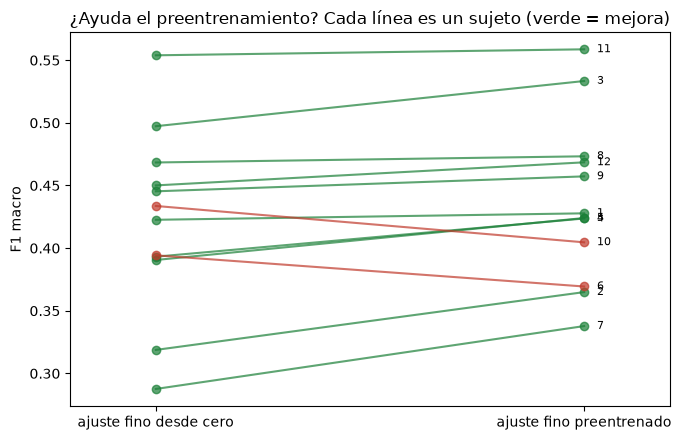

In [19]:
pairs = [("ajuste fino preentrenado", "ajuste fino desde cero"),
         ("ajuste fino preentrenado", "características manuales (sonda)"),
         ("ajuste fino desde cero", "características manuales (sonda)"),
         ("CPC congelado (sonda)", "red sin entrenar (sonda)"),
         ("CPC congelado (sonda)", "características manuales (sonda)")]
rng = np.random.default_rng(SEED_DATA)
rows = []
for a, b in pairs:
    diff = (by_subject[a] - by_subject[b]).dropna().to_numpy()
    boot = np.array([rng.choice(diff, len(diff)).mean() for _ in range(5000)])
    p = wilcoxon(diff).pvalue if len(diff) >= 5 and np.any(diff != 0) else np.nan
    rows.append({"comparación": f"{a} − {b}", "diferencia media": diff.mean(),
                 "IC 95 %": f"[{np.quantile(boot, .025):+.3f}, {np.quantile(boot, .975):+.3f}]",
                 "sujetos en que gana": f"{int((diff > 0).sum())} de {len(diff)}", "p (Wilcoxon)": p})
display(pd.DataFrame(rows).set_index("comparación").round({"diferencia media": 3, "p (Wilcoxon)": 4}))

fig, ax = plt.subplots(figsize=(7, 4.5))
a, b = pairs[0]
for s in by_subject.index:
    ax.plot([0, 1], [by_subject.loc[s, b], by_subject.loc[s, a]], marker="o",
            color="#1a7f37" if by_subject.loc[s, a] > by_subject.loc[s, b] else "#c0392b", alpha=0.7)
    ax.text(1.03, by_subject.loc[s, a], str(s), va="center", fontsize=8)
ax.set(xticks=[0, 1], xticklabels=[b, a], xlim=(-0.2, 1.2), ylabel="F1 macro",
       title="¿Ayuda el preentrenamiento? Cada línea es un sujeto (verde = mejora)")
plt.tight_layout()
plt.show()

# 9. Desempeño por actividad

Se juntan las predicciones de los 12 sujetos evaluados (cada uno predicho por el modelo que no lo vio) y se calcula el F1 por actividad y la matriz de confusión del mejor método. Con las semillas disponibles se promedia el F1 y se suma la matriz.

,N,LF,K,PT,LT,W,PF,F1 macro
ajuste fino preentrenado,0.712,0.423,0.485,0.361,0.398,0.390,0.376,0.449
ajuste fino desde cero,0.722,0.394,0.442,0.351,0.405,0.385,0.338,0.434
CPC congelado (sonda),0.665,0.398,0.450,0.318,0.355,0.322,0.327,0.405
red sin entrenar (sonda),0.639,0.377,0.414,0.311,0.346,0.329,0.332,0.393
características manuales (sonda),0.636,0.344,0.469,0.281,0.363,0.318,0.350,0.394


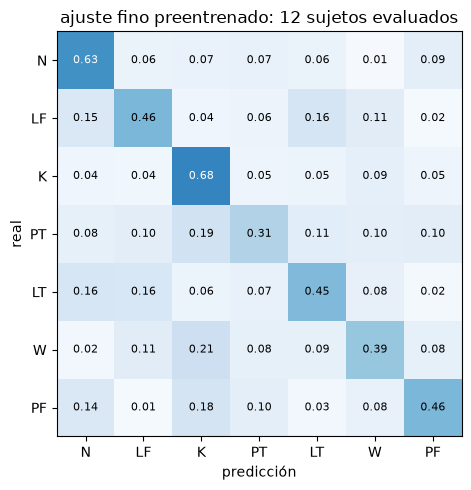

Comparación con el notebook 06 (validación con los sujetos 11 y 12, ajuste fino preentrenado sLSTM B):


,notebook 06,LOSO (este notebook)
11,0.603,0.559
12,0.483,0.468


In [20]:
def pooled(method):
    per_seed, cms = [], []
    for seed in sorted({r["seed"] for r in runs}):
        rs = [r for r in runs if r["seed"] == seed]
        y = np.concatenate([r["y"] for r in rs]); p = np.concatenate([r["pred"][method] for r in rs])
        per_seed.append(f1_score(y, p, labels=range(len(LABELS)), average=None, zero_division=0))
        cms.append(confusion_matrix(y, p, labels=range(len(LABELS))))
    cm = np.sum(cms, axis=0)
    return np.mean(per_seed, axis=0), cm / cm.sum(axis=1, keepdims=True)

per_class = pd.DataFrame({m: pooled(m)[0] for m in METHODS}, index=LABELS).T
per_class["F1 macro"] = per_class.mean(axis=1)
display(per_class.round(3))

best_method = per_class["F1 macro"].idxmax()
cm = pooled(best_method)[1]
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(len(LABELS)), xticklabels=LABELS, yticks=range(len(LABELS)), yticklabels=LABELS,
       xlabel="predicción", ylabel="real", title=f"{best_method}: 12 sujetos evaluados")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.55 else "black")
plt.tight_layout()
plt.show()

print("Comparación con el notebook 06 (validación con los sujetos 11 y 12, ajuste fino preentrenado sLSTM B):")
display(pd.DataFrame({"notebook 06": {11: 0.603, 12: 0.483},
                      "LOSO (este notebook)": by_subject["ajuste fino preentrenado"].reindex([11, 12])}).round(3))

# 10. ¿Qué tan bien predice CPC la señal?

Las secciones anteriores miden la **clasificación de actividades**. Esta sección mide la **tarea propia de CPC**: dado el contexto `c_t` de una ventana, reconocer cuál es el futuro real de la señal (`z_{t+k}`) entre 128 candidatos.

Para cada uno de los 24 modelos guardados (12 rondas × 2 semillas):

- se usa el **sujeto evaluado** de esa ronda, que el modelo nunca vio, con el escalador de la ronda;
- se forman 40 lotes de 128 recortes aleatorios de ese sujeto: todos los candidatos son de **la misma persona**, como en el entrenamiento, que es la versión difícil de la tarea;
- se mide la **accuracy contrastiva** (cuántas veces el futuro correcto obtiene la mayor similitud) y la pérdida InfoNCE, para cada horizonte `k`;
- se repite con **la misma red sin entrenar** (mismos pesos iniciales) como referencia.

El **azar** es 1/128 ≈ 0.8 % de accuracy y una pérdida de log(128) ≈ 4.85.

Tarea de CPC en el sujeto evaluado (media y desviación de los 24 modelos):


pérdida        accuracy       
                    mean    std     mean    std
modelo                                         
CPC                2.677  0.396    0.313  0.102
red sin entrenar   4.871  0.005    0.008  0.000
azar               4.852  0.000    0.008  0.000

Accuracy por horizonte de predicción:


,83 ms,167 ms,250 ms,333 ms,417 ms,500 ms,583 ms,667 ms,750 ms,833 ms,917 ms,1000 ms
modelo,,,,,,,,,,,,
CPC,0.627,0.561,0.468,0.383,0.315,0.266,0.235,0.211,0.193,0.177,0.166,0.156
red sin entrenar,0.007,0.009,0.006,0.005,0.008,0.008,0.010,0.009,0.008,0.007,0.009,0.007
azar,0.008,0.008,0.008,0.008,0.008,0.008,0.008,0.008,0.008,0.008,0.008,0.008


Accuracy de CPC por sujeto evaluado:


sujeto,1,2,3,4,5,6,7,8,9,10,11,12
accuracy,0.327,0.287,0.431,0.27,0.399,0.273,0.236,0.309,0.347,0.345,0.288,0.246


¿Los sujetos en que CPC predice mejor son los que se clasifican mejor?


,ρ de Spearman,p
F1 de,,
ajuste fino preentrenado,0.43,0.17
CPC congelado (sonda),0.15,0.63


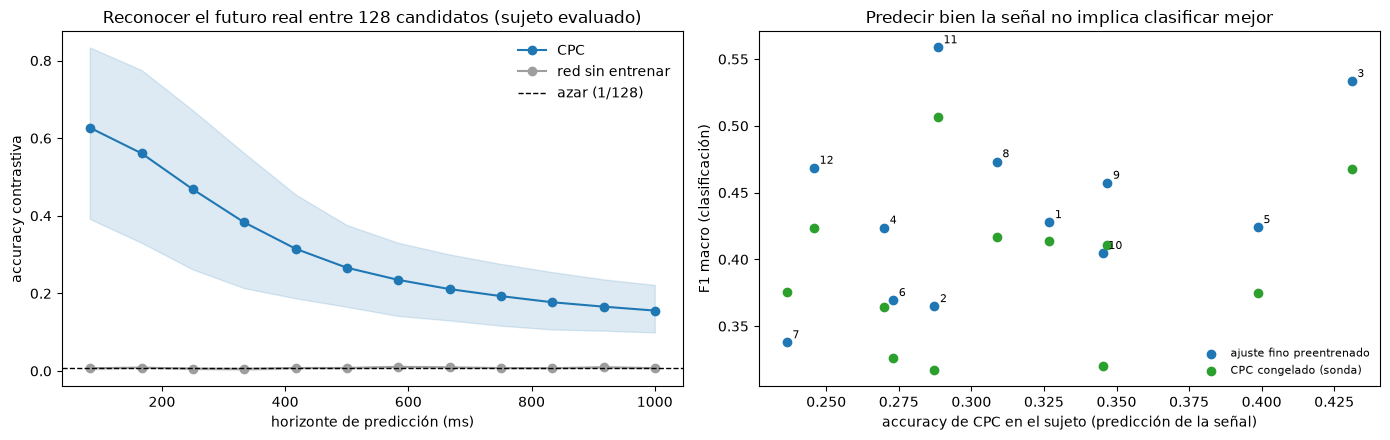

In [21]:
B_EVAL, N_BATCH_EVAL = 128, 40
rows = []
for path in sorted(RUN_DIR.glob("ronda_*.pt")):
    ckpt = torch.load(path, map_location=DEVICE)
    r = json.loads(path.with_suffix(".json").read_text())
    set_series(apply_scaler(ckpt["scaler"]))
    pool = CPCBatchSampler((r["held_out"],), "mezclado", 0).starts      # todos los inicios válidos del sujeto evaluado
    for name in ("CPC", "red sin entrenar"):
        model = build_model(KIND, HORIZONS, r["seed"])
        if name == "CPC":
            model.load_state_dict(ckpt["cpc"])
        model.eval()
        g = np.random.default_rng(123)
        lo, hi = model.anchor_range(WIN)
        losses, accs = [], []
        with torch.no_grad():
            for _ in range(N_BATCH_EVAL):
                x = get_windows(g.choice(pool, B_EVAL, replace=False))
                anchors = g.integers(lo, hi, size=model.cfg.n_anchors).tolist()
                _, loss_k, acc_k = model.info_nce(x, anchors=anchors)
                losses.append(loss_k.cpu().numpy())
                accs.append(acc_k.cpu().numpy())
        acc_k, loss_k = np.mean(accs, axis=0), np.mean(losses, axis=0)
        rows.append({"sujeto": r["held_out"], "semilla": r["seed"], "modelo": name,
                     "pérdida": loss_k.mean(), "accuracy": acc_k.mean(),
                     **{f"{1000 * k / TARGET_FS:.0f} ms": a for k, a in zip(HORIZONS, acc_k)}})
        del model
cpc_task = pd.DataFrame(rows)
horizon_cols = [c for c in cpc_task.columns if c.endswith(" ms")]

summary_task = cpc_task.groupby("modelo")[["pérdida", "accuracy"]].agg(["mean", "std"])
summary_task.loc["azar"] = [math.log(B_EVAL), 0.0, 1 / B_EVAL, 0.0]
print("Tarea de CPC en el sujeto evaluado (media y desviación de los 24 modelos):")
display(summary_task.round(3))

by_horizon = cpc_task.groupby("modelo")[horizon_cols].mean().T
by_horizon["azar"] = 1 / B_EVAL
print("Accuracy por horizonte de predicción:")
display(by_horizon.round(3).T)

acc_subject = cpc_task[cpc_task["modelo"] == "CPC"].groupby("sujeto")["accuracy"].mean()
print("Accuracy de CPC por sujeto evaluado:")
display(acc_subject.round(3).to_frame().T)

from scipy.stats import spearmanr
corr_rows = []
for m in ("ajuste fino preentrenado", "CPC congelado (sonda)"):
    rho = spearmanr(acc_subject, by_subject.loc[acc_subject.index, m])
    corr_rows.append({"F1 de": m, "ρ de Spearman": rho.statistic, "p": rho.pvalue})
print("¿Los sujetos en que CPC predice mejor son los que se clasifican mejor?")
display(pd.DataFrame(corr_rows).set_index("F1 de").round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ms = [int(c.split()[0]) for c in horizon_cols]
for name, color in (("CPC", "#1f77b4"), ("red sin entrenar", "#9e9e9e")):
    sub = cpc_task[cpc_task["modelo"] == name][horizon_cols]
    axes[0].plot(ms, sub.mean(), marker="o", color=color, label=name)
    axes[0].fill_between(ms, sub.quantile(0.1), sub.quantile(0.9), color=color, alpha=0.15)
axes[0].axhline(1 / B_EVAL, color="black", ls="--", lw=1, label="azar (1/128)")
axes[0].set(xlabel="horizonte de predicción (ms)", ylabel="accuracy contrastiva",
            title="Reconocer el futuro real entre 128 candidatos (sujeto evaluado)")
axes[0].legend(frameon=False)
for m, color in (("ajuste fino preentrenado", "#1f77b4"), ("CPC congelado (sonda)", "#2ca02c")):
    axes[1].scatter(acc_subject, by_subject.loc[acc_subject.index, m], color=color, label=m)
for s in acc_subject.index:
    axes[1].annotate(str(s), (acc_subject[s], by_subject.loc[s, "ajuste fino preentrenado"]),
                     textcoords="offset points", xytext=(4, 3), fontsize=8)
axes[1].set(xlabel="accuracy de CPC en el sujeto (predicción de la señal)", ylabel="F1 macro (clasificación)",
            title="Predecir bien la señal no implica clasificar mejor")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Lectura del resultado:**

- **CPC aprende bien su tarea y la generaliza a personas nuevas.** En el sujeto evaluado, que el modelo nunca vio, reconoce el futuro real de la señal entre 128 candidatos el **31 %** de las veces, unas 40 veces el azar (0.8 %), con una pérdida de 2.68 frente a 4.85 del azar. La misma red sin entrenar queda exactamente en el nivel del azar.
- **Predice muy bien a corto plazo y peor a largo plazo.** Acierta el **63 %** a 83 ms, el 47 % a 250 ms, el 27 % a 500 ms y el 16 % a 1 s, que todavía es unas 20 veces el azar. Es lo esperado: el futuro inmediato de una envolvente que cambia lentamente es fácil de anticipar; el lejano depende de lo que la persona haga después. La banda sombreada (percentiles 10–90 de los 24 modelos) muestra que la variación entre sujetos y semillas es grande en los horizontes cortos.
- **Predecir bien la señal no se traduce en clasificar mejor.** Por sujeto, la accuracy de CPC va del 24 % (sujetos 7 y 12) al 43 % (sujeto 3), pero no se relaciona claramente con el F1 de clasificación (ρ = 0.43, p = 0.17 con el ajuste fino; ρ = 0.15, p = 0.63 con CPC congelado). El sujeto 12, por ejemplo, es de los más difíciles de predecir y de los mejor clasificados.
- **Interpretación:** para anticipar los próximos cientos de milisegundos de la envolvente basta con información **local**, como el nivel actual y si va subiendo o bajando. CPC aprende muy bien esa "inercia" de la señal, pero eso no requiere saber qué actividad se está haciendo: actividades distintas pueden tener la misma tendencia local. Por eso, en la sección 8, CPC congelado no supera a la red sin entrenar en clasificación aunque en esta tarea la supere ampliamente.
- **Implicación:** el preentrenamiento CPC sirve como punto de partida para el ajuste fino, pero no como representación de actividades por sí solo. Si la sEMG del miembro superior no contiene la información de postura que separa las actividades confundidas, ni un mejor preentrenamiento ni una mejor arquitectura la van a crear; hace falta otra fuente de información, como la captura de movimiento (MVNX).

# 11. Cómo leer los resultados

- **Desempeño esperado en una persona nueva:** la media de la sección 7 para el ajuste fino preentrenado. La desviación entre sujetos dice cuánto puede variar de una persona a otra; el mínimo, qué tan mal puede ir en el peor caso.
- **¿Ayuda el preentrenamiento?** Primera fila de la sección 8. Se considera establecido si el intervalo de confianza no incluye el 0, la ventaja aparece en la mayoría de los sujetos y el p de Wilcoxon es < 0.05. Si no, la conclusión honesta es que preentrenar y entrenar desde cero rinden igual con estos datos.
- **¿Supera a las características manuales?** Segunda y tercera filas. Es la referencia clásica: si el modelo no la supera en la mayoría de los sujetos, la representación aprendida no justifica su costo.
- **¿Qué aprende CPC por sí solo?** Cuarta fila: CPC congelado contra la misma red sin entrenar, ambas con el mismo clasificador lineal.
- **Sujetos difíciles:** los de F1 bajo en todos los métodos tienen señales atípicas (colocación de electrodos, forma de moverse); los que sólo fallan en un método indican un problema de ese método.
- **Coherencia con el notebook 06:** los sujetos 11 y 12 deberían dar valores parecidos a los del 06. No serán idénticos: aquí el modelo se entrena con 10 sujetos distintos y con otra validación interna.
- **Siguiente paso:** con la configuración validada, entrenar el modelo final con los 12 sujetos (o promediar los modelos de las rondas como ensamble) y **abrir la prueba (13–14) una sola vez**.